# Clase 6 — Desafío grupal: Retrieval Engineering

## Caso: NexoGuide, el asistente interno de NexoCorp

NexoCorp quiere construir **NexoGuide**, un asistente interno que responda preguntas de empleados usando políticas y procedimientos corporativos.

Antes de conectarlo a un LLM, el equipo necesita responder:

> **¿Nuestro retriever recupera la evidencia correcta, suficiente y vigente?**

El corpus incluye **desafíos distintos de retrieval**:

- versiones obsoletas que compiten con las vigentes;
- documentos activos de dominios parecidos;
- preguntas que necesitan **más evidencia que el `top_k` inicial**;
- preguntas cuya respuesta **no existe**, pero el vector store igual puede devolver algo parecido;
- metadata que puede ayudar, pero que también puede destruir Recall si se usa mal.

### Objetivo

**medir → diagnosticar → formular hipótesis → cambiar UNA variable → volver a medir**

🚫 No se puede cambiar el modelo de embeddings.

✅ Sí se puede experimentar con `CHUNK_SIZE`, `OVERLAP`, `TOP_K`, `FILTERS` y `THRESHOLD`.

**Duración:** 50–60 minutos.

## 0. Preparación

Desde la carpeta de la actividad:

```bash
pip install -r requirements.txt
```

> La primera ejecución puede descargar `sentence-transformers/all-MiniLM-L6-v2`.

Primero conozcan el caso y los datos. Luego calculen el baseline que usarán como referencia.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

from src.retrieval_lab import (
    DocumentRetriever,
    run_evaluation,
    corpus_catalog,
    document_preview,
    load_cases,
    inspect_case_results,
)

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"

previous_retriever = globals().get("retriever")
if previous_retriever is not None:
    close_method = getattr(previous_retriever, "close", None)
    if callable(close_method):
        close_method()

retriever = DocumentRetriever(data_dir=BASE_DIR)
print("✅ Laboratorio listo")

/Users/gasparcartasso/Desktop/AI Developer/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 18680.04it/s]


✅ Laboratorio listo


# Paso 1 — Conocer el corpus

Antes de medir nada, miren **qué información tiene NexoGuide disponible**.

Esta tabla muestra una fila por documento. Presten especial atención a:

- `department` y `topic`: dominio del documento.
- `active`: si puede considerarse vigente.
- `version` y `effective_from`: versión temporal.
- `audience`, `country` y `confidentiality`: metadata que en un sistema real podría condicionar elegibilidad.
- `n_sections`: cuántas unidades lógicas de evidencia contiene.
- `content_hash`: huella del contenido; sirve para detectar si un documento cambió, aunque **no participa del ranking semántico**.

In [2]:
catalogo = pd.DataFrame(corpus_catalog(BASE_DIR))

display(
    catalogo[[
        "document_id", "title", "department", "topic",
        "active", "version", "effective_from",
        "audience", "country", "n_sections", "content_hash"
    ]]
)

print(f"Documentos: {len(catalogo)}")
print(f"Vigentes:   {int(catalogo['active'].eq(True).sum())}")
print(f"Obsoletos:  {int(catalogo['active'].eq(False).sum())}")
print("\nDocumentos por dominio:")
display(catalogo.groupby("department").size().rename("documentos").to_frame())

,document_id,title,department,topic,active,version,effective_from,audience,country,n_sections,content_hash
0,VAC-2024,Política de vacaciones 2024,rrhh,vacaciones,False,2024.1,2024-01-01,empleados,AR,4,b863c6fc48
1,VAC-2026,Política corporativa de descanso anual,rrhh,vacaciones,True,2026.2,2026-01-01,empleados,AR,4,1c547dbffd
2,HYB-2024,Guía de home office 2024,rrhh,trabajo_hibrido,False,2024.3,2024-03-01,empleados,AR,3,d284e7bb88
3,HYB-2026,Política de Trabajo Híbrido,NaN,rrhh,True,2026.1,NaN,NaN,NaN,4,171eb23142
4,SEC-REMOTE-2026,Seguridad y Acceso Remoto,NaN,it,True,2026.3,NaN,NaN,NaN,4,87ab2778a7
5,HYB-2026,Marco de trabajo híbrido 2026,rrhh,trabajo_hibrido,True,2026.1,2026-02-01,empleados,AR,4,0d1d2855b5
6,EXP-LOCAL-2026,Política de Gastos Locales y Reintegros,NaN,finanzas,True,2026.1,NaN,NaN,NaN,4,66a6d984b0
7,SEC-REMOTE-2026,Estándar de acceso remoto seguro,tecnologia,seguridad,True,2026.4,2026-04-15,empleados,GLOBAL,4,d63e49522f
8,EXP-LOCAL-2026,Política de gastos locales y reintegros,finanzas,gastos,True,2026.3,2026-03-01,empleados,AR,4,87d76a5c87
9,TRV-2026,Política de Viajes Corporativos,NaN,finanzas,True,2026.2,NaN,NaN,NaN,4,7d443e8cbf


Documentos: 29
Vigentes:   26
Obsoletos:  3

Documentos por dominio:


,documentos
department,
compras,1
finanzas,2
legal,1
rrhh,9
tecnologia,5
workplace,1


### Mirar documentos reales, no solo IDs

Inspeccionen estos dos pares de documentos:

1. **Vacaciones 2024 vs. 2026**: semánticamente hablan de lo mismo, pero solo una versión está vigente.
2. **Home office 2024 vs. trabajo híbrido 2026**: la versión vieja usa palabras que probablemente se parecen más a algunas queries.

Esto permite discutir una idea central de la clase:

> **similitud semántica no equivale a validez de negocio.**

In [3]:
def mostrar_documento(document_id):
    doc = document_preview(BASE_DIR, document_id)
    meta = doc["metadata"]

    print("=" * 90)
    print(f"{meta.get('title')}  |  document_id={meta.get('document_id')}")
    print(
        f"department={meta.get('department')} | topic={meta.get('topic')} | "
        f"active={meta.get('active')} | version={meta.get('version')} | "
        f"effective_from={meta.get('effective_from')}"
    )
    print("-" * 90)

    for section in doc["sections"]:
        print(f"[{section['section_id']}] {section['section_title']}")
        print(section["text"])
        print()

mostrar_documento("VAC-2024")
mostrar_documento("VAC-2026")

Política de vacaciones 2024  |  document_id=VAC-2024
department=rrhh | topic=vacaciones | active=False | version=2024.1 | effective_from=2024-01-01
------------------------------------------------------------------------------------------
[VAC24_DIAS] Días disponibles
¿Cuántos días de vacaciones tengo por año? Los colaboradores cuentan con 15 días hábiles de vacaciones por año calendario.

[VAC24_SOLICITUD] Anticipación de la solicitud
Las vacaciones deben solicitarse con al menos 15 días corridos de anticipación y quedan sujetas a aprobación del responsable.

[VAC24_ARRASTRE] Arrastre
Se pueden trasladar hasta 10 días hábiles al año siguiente. Los días trasladados deben utilizarse antes del 30 de junio.

[VAC24_CAMBIOS] Cambios y cancelaciones
Los cambios sobre vacaciones ya aprobadas deben gestionarse con el líder y People Operations.

Política corporativa de descanso anual  |  document_id=VAC-2026
department=rrhh | topic=vacaciones | active=True | version=2026.2 | effective_from=202

## Una aclaración importante: ❌ no significa “filtrado”

En las tablas de diagnóstico vamos a usar:

- **✅ relevante_ground_truth**: el resultado pertenece a la evidencia esperada para esa query.
- **❌ relevante_ground_truth**: el resultado fue recuperado, pero **no forma parte del ground truth**.

Esto es distinto de un filtro.

Si aplicamos `FILTERS={"active": True}`, un documento con `active=False` **debería desaparecer del ranking**. No debería “convertirse” de ❌ a ✅.

Esta diferencia es central:

> **Ground truth evalúa si el resultado es correcto. El filtro decide si un documento puede competir.**

# Paso 2 — Entender el golden dataset

Ahora miramos **cómo vamos a evaluar**.

Un caso de evaluación tiene:

- una `query`;
- un `case_type`, para saber qué comportamiento estamos probando;
- `relevant_section_ids`, que define el **ground truth**.

### ¿Por qué usamos `section_id` y no el UUID exacto del chunk?

Porque durante la actividad ustedes pueden cambiar `CHUNK_SIZE` y `OVERLAP`.

Si el ground truth dependiera del UUID del chunk, cambiar el chunking rompería la evaluación. En cambio, el `section_id` representa una **unidad lógica estable de evidencia** y se propaga a los chunks que nazcan de esa sección.

In [4]:
golden = pd.DataFrame(load_cases(DATA_DIR))

golden["respondible"] = golden["relevant_section_ids"].map(bool)

display(
    golden[[
        "case_id", "query", "case_type",
        "respondible", "relevant_section_ids"
    ]]
)

print("Tipos de casos:")
display(golden.groupby("case_type").size().rename("cantidad").to_frame())

,case_id,query,case_type,respondible,relevant_section_ids
0,Q01,¿Cuántos días de vacaciones tengo por año?,conflicto_version,True,[VAC26_DIAS]
1,Q02,¿Con cuánta anticipación tengo que pedir vacac...,conflicto_version,True,[VAC26_SOLICITUD]
2,Q03,¿Puedo pasar días de vacaciones al año siguiente?,conflicto_version,True,[VAC26_ARRASTRE]
3,Q04,¿Cuántos días puedo hacer home office?,sinonimo_y_version,True,[HYB26_DIAS]
4,Q05,¿Puedo trabajar remotamente desde Uruguay una ...,restriccion,True,[HYB26_EXTERIOR]
5,Q06,¿Cómo me conecto a los sistemas internos desde...,cross_domain,True,[SEC_VPN]
6,Q07,¿Puedo entrar a producción desde mi notebook p...,seguridad,True,[SEC_DISPOSITIVOS]
7,Q08,¿Cuál es el tope por persona para una comida d...,ambiguedad_contexto,True,[EXP_LOCAL_COMIDAS]
8,Q09,"Estoy de viaje con pernocte, ¿cuánto puedo ren...",ambiguedad_contexto,True,[TRV_COMIDAS]
9,Q10,¿Cuántos días adicionales da la empresa por na...,directa,True,[LEAVE_PARENTAL]


Tipos de casos:


,cantidad
case_type,
ambiguedad_contexto,2
conflicto_version,4
coverage_top_k,1
cross_domain,1
directa,4
domain_collision,1
evidencia_multiple,2
multiple_evidences,1
regla_numerica,1


### Cómo se calculan las métricas

Para cada query del golden dataset:

1. el retriever devuelve su ranking;
2. comparamos los `section_id` recuperados con los `relevant_section_ids`;
3. calculamos las métricas.

Ejemplo conceptual:

```text
Ground truth: [VAC26_DIAS]

Ranking:
1. VAC24_DIAS   ❌
2. VAC26_DIAS   ✅
3. HYB24_DIAS   ❌
```

Con `k=3`:

- **Precision@3 = 1/3**
- **Recall@3 = 1/1**
- **RR = 1/2**, porque el primer relevante aparece segundo.

El **MRR** es el promedio del RR sobre todas las queries respondibles.

Las queries con `relevant_section_ids=[]` se usan para evaluar **abstención**.

# Fase 1 — Medir el baseline
⏱️ **10 minutos**

Ahora sí.

Todos los equipos parten de **la misma configuración**. No la modifiquen todavía.

El baseline es nuestra línea de base reproducible.

In [5]:
CHUNK_SIZE = 70
OVERLAP = 0
TOP_K = 3
FILTERS = {}
THRESHOLD = None

baseline = run_evaluation(
    retriever=retriever,
    data_dir=DATA_DIR,
    chunk_size_words=CHUNK_SIZE,
    overlap_words=OVERLAP,
    top_k=TOP_K,
    global_filters=FILTERS,
    score_threshold=THRESHOLD,
    save_report=False,
)

s = baseline["summary"]

display(pd.DataFrame([{
    "Chunks": s["n_chunks"],
    f"Precision@{TOP_K}": round(s["precision_at_k"], 3),
    f"Recall@{TOP_K}": round(s["recall_at_k"], 3),
    "MRR": round(s["mrr"], 3),
    "Hit@1": round(s["hit_at_1"], 3),
    "Abstención": round(s["abstention_accuracy"], 3),
    "Latencia búsqueda media ms": round(s["latency_mean_ms"], 1),
    "p95 búsqueda ms": round(s["latency_p95_ms"], 1),
}]))

print("Configuración medida:")
print(s["config"])

Batches: 100%|██████████| 4/4 [00:01<00:00,  3.14it/s]


,Chunks,Precision@3,Recall@3,MRR,Hit@1,Abstención,Latencia búsqueda media ms,p95 búsqueda ms
0,109,0.275,0.507,0.507,0.435,0.0,0.4,0.4


Configuración medida:
{'model': 'sentence-transformers/all-MiniLM-L6-v2', 'chunk_size_words': 70, 'overlap_words': 0, 'top_k': 3, 'filters': {}, 'score_threshold': None}


### Importante sobre la latencia

En este laboratorio, la latencia registrada mide **la búsqueda en Qdrant una vez generado el embedding de la query**.

No representa todavía toda la latencia end-to-end de una aplicación RAG.

### Lectura rápida de las métricas

- **Precision baja:** hay ruido.
- **Recall bajo:** falta evidencia relevante.
- **MRR bajo:** la evidencia correcta aparece tarde.
- **Abstención baja:** el retriever fuerza resultados incluso cuando no hay evidencia suficiente.

## Señal 1 — ¿Por qué la abstención del baseline da 0?

Con:

```python
THRESHOLD = None
```

Qdrant devuelve los mejores candidatos aunque ninguno sea suficientemente bueno.

Por eso, con un corpus grande, una query sin respuesta normalmente recibe resultados y:

```text
abstention_accuracy = 0
```

**No es un error de ejecución:** el baseline todavía no tiene una regla para abstenerse.

Para experimentar con abstención primero necesitamos mirar la distribución de scores.

In [6]:
casos_base = pd.DataFrame(baseline["cases"]).copy()
casos_base["respondible"] = casos_base["relevant_section_ids"].map(bool)

display(
    casos_base[[
        "case_id", "query", "respondible",
        "max_score", "returned_count",
        "relevant_section_ids", "retrieved_section_ids"
    ]].sort_values(["respondible", "max_score"])
)

print("Resumen de score máximo por tipo de query:")
display(
    casos_base.groupby("respondible")["max_score"]
    .agg(["min", "median", "max", "mean", "count"])
    .rename(index={True: "Respondible", False: "Sin respuesta"})
    .round(4)
)

,case_id,query,respondible,max_score,returned_count,relevant_section_ids,retrieved_section_ids
25,Q26,¿La empresa paga una membresía mensual de gimn...,False,0.4938,3,[],"[EXP_EXCEPCIONES, HYB_DIAS, INF_REMOTO]"
19,Q20,¿Todos los empleados reciben stock options?,False,0.5216,3,[],"[HYB24_EXTERIOR, TRV_COMIDAS, BEN_SALUD]"
18,Q19,¿La empresa cubre la guardería de mis hijos?,False,0.5242,3,[],"[ETH_NO_REPRESALIA, HYB24_DIAS, INF_REMOTO]"
20,Q21,¿La empresa ofrece estacionamiento gratuito?,False,0.5382,3,[],"[ETH_NO_REPRESALIA, BEN_SALUD, HYB_EQUIPO]"
24,Q25,¿Los empleados tienen estacionamiento gratuito...,False,0.6252,3,[],"[VAC24_DIAS, VAC24_ARRASTRE, LEAVE_ESTUDIO]"
14,Q15,¿Dónde puedo denunciar una situación de acoso ...,True,0.5365,3,[ETH_REPORTE],"[ETH_REPORTE, ETH_REPORTE, BEN_COMEDOR]"
9,Q10,¿Cuántos días adicionales da la empresa por na...,True,0.5645,3,[LEAVE_PARENTAL],"[HYB_EQUIPO, HYB24_DIAS, TRV_CAMBIOS]"
13,Q14,No me funciona el segundo factor y no tengo ni...,True,0.5768,3,"[HELP_MFA, SEC_MFA]","[HELP_MFA, LEAVE_DUELO, HYB24_EXTERIOR]"
16,Q17,¿La empresa me reintegra un curso externo rela...,True,0.5811,3,[LEARN_REINTEGRO],"[LEARN_REINTEGRO, HYB26_EQUIPO, EXP_COMIDAS]"
27,Q28,¿Qué límites de comida existen según sea una c...,True,0.5847,3,"[EVT_COMIDAS, EXP_LOCAL_COMIDAS, TRV_COMIDAS]","[TRV_COMIDAS, TRV_COMIDAS, BEN_COMEDOR]"


Resumen de score máximo por tipo de query:


,min,median,max,mean,count
respondible,,,,,
Sin respuesta,0.4938,0.5242,0.6252,0.5406,5
Respondible,0.5365,0.6554,0.8581,0.6684,23


array([<Axes: title={'center': 'False'}, ylabel='Frequency'>,
       <Axes: title={'center': 'True'}, ylabel='Frequency'>], dtype=object)

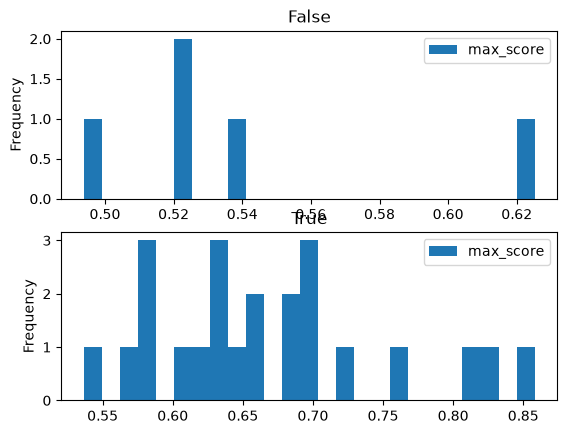

In [15]:
casos_base.plot.hist(column='max_score',by='respondible', bins=25,legend=True)

## Decision threshold tuning

El threshold debe estar entre el minimo de Respondible y el maximo de Sin Respuesta.
Como se 'pisan' debemos tomar 

### Cómo pensar un threshold

Busquen una zona que separe, lo mejor posible:

```text
queries respondibles  → score alto
queries sin respuesta → score más bajo
```

Si el threshold es demasiado bajo, **no abstiene**.

Si es demasiado alto, empieza a descartar evidencia válida y **baja Recall**.

No existe un número correcto universal: se calibra con este corpus y este golden dataset.

## Señal 2 — `top_k=3` tiene un límite estructural

Miren especialmente **Q23**.

Esa pregunta tiene **4 unidades de evidencia relevantes**:

```text
HYB26_EXTERIOR
SEC_VPN
SEC_DISPOSITIVOS
INF_REMOTO
```

Con `TOP_K = 3`, aunque los tres resultados fueran perfectos:

```text
Recall@3 máximo = 3 / 4 = 0,75
```

Acá no hay un problema de embeddings: **pedimos menos resultados que la cantidad de evidencia que necesitamos**.

Por lo tanto, `top_k` limita la cobertura máxima posible y debe elegirse según la cantidad de evidencia que requiera la consulta.

## Señal 3 — El filtro de vigencia debe verse en ranking, no solo en Precision@3

En preguntas con **un único relevante**, una configuración perfecta con `TOP_K=3` puede seguir dando:

```text
Precision@3 = 1/3 = 0,333
```

Para observar la calidad del primer resultado usamos **Hit@1**:

> **Hit@1 = 1** si el primer resultado es relevante.

El filtro `active=True` puede sacar una política vieja del primer puesto y mejorar **Hit@1 / MRR**, aunque Precision@3 permanezca igual.

En queries amplias como **Q22**, que tiene tres evidencias vigentes de vacaciones, el efecto sobre Precision@3 puede ser más visible.

# Fase 2 — Diagnosticar
⏱️ **10–15 minutos**

Primero miren **todos los casos**. No optimicen mirando solamente el promedio.

In [16]:
casos = pd.DataFrame(baseline["cases"])

vista = casos[[
    "case_id", "query", "case_type",
    "relevant_section_ids", "retrieved_section_ids",
    "retrieved_document_ids", "retrieved_active",
    "precision_at_k", "recall_at_k", "rr", "hit_at_1", "max_score"
]].copy()

display(vista)

,case_id,query,case_type,relevant_section_ids,retrieved_section_ids,retrieved_document_ids,retrieved_active,precision_at_k,recall_at_k,rr,hit_at_1,max_score
0,Q01,¿Cuántos días de vacaciones tengo por año?,conflicto_version,[VAC26_DIAS],"[VAC24_DIAS, VAC24_ARRASTRE, HYB24_DIAS]","[VAC-2024, VAC-2024, HYB-2024]","[False, False, False]",0.000000,0.000000,0.000000,0.0,0.8146
1,Q02,¿Con cuánta anticipación tengo que pedir vacac...,conflicto_version,[VAC26_SOLICITUD],"[VAC24_SOLICITUD, BEN_COMEDOR, VAC26_SOLICITUD]","[VAC-2024, BEN-2026, VAC-2026]","[False, True, True]",0.333333,1.000000,0.333333,0.0,0.6237
2,Q03,¿Puedo pasar días de vacaciones al año siguiente?,conflicto_version,[VAC26_ARRASTRE],"[VAC24_DIAS, VAC24_ARRASTRE, LEAVE_DUELO]","[VAC-2024, VAC-2024, LEAVE-2026]","[False, False, True]",0.000000,0.000000,0.000000,0.0,0.7275
3,Q04,¿Cuántos días puedo hacer home office?,sinonimo_y_version,[HYB26_DIAS],"[HYB24_DIAS, HYB24_HORARIO, LEAVE_ESTUDIO]","[HYB-2024, HYB-2024, LEAVE-2026]","[False, False, True]",0.000000,0.000000,0.000000,0.0,0.8581
4,Q05,¿Puedo trabajar remotamente desde Uruguay una ...,restriccion,[HYB26_EXTERIOR],"[HYB24_EXTERIOR, HYB_UBICACION, EXP_LOCAL_COMI...","[HYB-2024, HYB-2026, EXP-LOCAL-2026]","[False, True, True]",0.000000,0.000000,0.000000,0.0,0.6402
5,Q06,¿Cómo me conecto a los sistemas internos desde...,cross_domain,[SEC_VPN],"[SEC24_VPN, HYB24_DIAS, BEN_SALUD]","[SEC-REMOTE-2024, HYB-2024, BEN-2026]","[False, False, True]",0.000000,0.000000,0.000000,0.0,0.8309
6,Q07,¿Puedo entrar a producción desde mi notebook p...,seguridad,[SEC_DISPOSITIVOS],"[HYB26_EQUIPO, SEC_DISPOSITIVOS, SEC_INCIDENTE]","[HYB-2026, SEC-REMOTE-2026, SEC-REMOTE-2026]","[True, True, True]",0.333333,1.000000,0.500000,0.0,0.6292
7,Q08,¿Cuál es el tope por persona para una comida d...,ambiguedad_contexto,[EXP_LOCAL_COMIDAS],"[EXP_LOCAL_COMIDAS, HYB_UBICACION, HYB24_EXTER...","[EXP-LOCAL-2026, HYB-2026, HYB-2024]","[True, True, False]",0.333333,1.000000,1.000000,1.0,0.7574
8,Q09,"Estoy de viaje con pernocte, ¿cuánto puedo ren...",ambiguedad_contexto,[TRV_COMIDAS],"[HYB24_DIAS, LEAVE_ESTUDIO, LEAVE_DUELO]","[HYB-2024, LEAVE-2026, LEAVE-2026]","[False, True, True]",0.000000,0.000000,0.000000,0.0,0.6293
9,Q10,¿Cuántos días adicionales da la empresa por na...,directa,[LEAVE_PARENTAL],"[HYB_EQUIPO, HYB24_DIAS, TRV_CAMBIOS]","[HYB-2026, HYB-2024, TRV-2026]","[True, False, True]",0.000000,0.000000,0.000000,0.0,0.5645


### Elegir los casos problemáticos

Buscamos los peores casos respondibles según:

1. posición del primer relevante (`rr`);
2. cobertura (`recall_at_k`);
3. pureza (`precision_at_k`).

Pero el siguiente paso **no es tocar un parámetro**.

El siguiente paso es **leer lo que recuperó**.

In [17]:
respondibles = casos[casos["relevant_section_ids"].map(bool)].copy()

peores = respondibles.sort_values(
    by=["rr", "recall_at_k", "precision_at_k"],
    ascending=True,
).head(5)

display(peores[[
    "case_id", "query", "case_type",
    "relevant_section_ids", "retrieved_section_ids",
    "retrieved_document_ids", "retrieved_active",
    "scores", "precision_at_k", "recall_at_k", "rr", "hit_at_1", "max_score"
]])

,case_id,query,case_type,relevant_section_ids,retrieved_section_ids,retrieved_document_ids,retrieved_active,scores,precision_at_k,recall_at_k,rr,hit_at_1,max_score
0,Q01,¿Cuántos días de vacaciones tengo por año?,conflicto_version,[VAC26_DIAS],"[VAC24_DIAS, VAC24_ARRASTRE, HYB24_DIAS]","[VAC-2024, VAC-2024, HYB-2024]","[False, False, False]","[0.8146, 0.6404, 0.603]",0.0,0.0,0.0,0.0,0.8146
2,Q03,¿Puedo pasar días de vacaciones al año siguiente?,conflicto_version,[VAC26_ARRASTRE],"[VAC24_DIAS, VAC24_ARRASTRE, LEAVE_DUELO]","[VAC-2024, VAC-2024, LEAVE-2026]","[False, False, True]","[0.7275, 0.6825, 0.6113]",0.0,0.0,0.0,0.0,0.7275
3,Q04,¿Cuántos días puedo hacer home office?,sinonimo_y_version,[HYB26_DIAS],"[HYB24_DIAS, HYB24_HORARIO, LEAVE_ESTUDIO]","[HYB-2024, HYB-2024, LEAVE-2026]","[False, False, True]","[0.8581, 0.6745, 0.5576]",0.0,0.0,0.0,0.0,0.8581
4,Q05,¿Puedo trabajar remotamente desde Uruguay una ...,restriccion,[HYB26_EXTERIOR],"[HYB24_EXTERIOR, HYB_UBICACION, EXP_LOCAL_COMI...","[HYB-2024, HYB-2026, EXP-LOCAL-2026]","[False, True, True]","[0.6402, 0.6097, 0.5899]",0.0,0.0,0.0,0.0,0.6402
5,Q06,¿Cómo me conecto a los sistemas internos desde...,cross_domain,[SEC_VPN],"[SEC24_VPN, HYB24_DIAS, BEN_SALUD]","[SEC-REMOTE-2024, HYB-2024, BEN-2026]","[False, False, True]","[0.8309, 0.6157, 0.5849]",0.0,0.0,0.0,0.0,0.8309


## Inspección profunda de una query

Esta es la parte más importante del diagnóstico.

No miren solamente:

```text
VAC24_DIAS
VAC26_DIAS
...
```

Miren también:

- documento;
- título;
- dominio;
- vigencia;
- versión;
- score;
- **texto exacto recuperado**.

Recién con esa evidencia formulamos una hipótesis.

In [18]:
CASE_ID = peores.iloc[0]["case_id"]

case_info, ranking = inspect_case_results(
    retriever=retriever,
    data_dir=DATA_DIR,
    case_id=CASE_ID,
    top_k=TOP_K,
    where=FILTERS,
    score_threshold=THRESHOLD,
)

print("CASO:", case_info["case_id"])
print("QUERY:", case_info["query"])
print("GROUND TRUTH:", case_info["relevant_section_ids"])
print("TIPO:", case_info["case_type"])
print()

ranking_df = pd.DataFrame(ranking)
display(ranking_df[[
    "rank", "relevante_ground_truth", "score", "section_id",
    "document_id", "title", "department",
    "active", "version", "text"
]])

CASO: Q01
QUERY: ¿Cuántos días de vacaciones tengo por año?
GROUND TRUTH: ['VAC26_DIAS']
TIPO: conflicto_version



,rank,relevante_ground_truth,score,section_id,document_id,title,department,active,version,text
0,1,❌,0.8146,VAC24_DIAS,VAC-2024,Política de vacaciones 2024,rrhh,False,2024.1,¿Cuántos días de vacaciones tengo por año? Los...
1,2,❌,0.6404,VAC24_ARRASTRE,VAC-2024,Política de vacaciones 2024,rrhh,False,2024.1,Se pueden trasladar hasta 10 días hábiles al a...
2,3,❌,0.6030,HYB24_DIAS,HYB-2024,Guía de home office 2024,rrhh,False,2024.3,¿Cuántos días puedo hacer home office? El esqu...


## Antes de tocar nada: escriban la hipótesis

Completen en una frase:

> **Creemos que la query ______ falla porque ______. Si cambiamos ______, debería mejorar ______ porque ______.**

Preguntas útiles:

- ¿El resultado esperado existe en el corpus?
- ¿Está compitiendo una versión obsoleta?
- ¿Está entrando contenido de otro dominio?
- ¿El resultado correcto aparece debajo del top-k?
- ¿El texto relevante quedó partido de una forma poco útil?
- ¿El filtro podría excluir evidencia válida?
- ¿El problema es realmente de relevancia o de abstención?

**Una hipótesis debe explicar el mecanismo, no solamente proponer un parámetro.**

# Fase 3 — Un experimento controlado
⏱️ **20–25 minutos**

Cambien **una decisión principal** y vuelvan a ejecutar exactamente el mismo golden dataset.

Ideas de experimentos:

| Intervención | Hipótesis que podría probar |
|---|---|
| `FILTERS = {"active": True}` | Los documentos obsoletos contaminan el ranking |
| subir `TOP_K` | La evidencia existe pero queda demasiado abajo |
| cambiar `CHUNK_SIZE` / `OVERLAP` | La unidad de evidencia está mal formada |
| agregar `THRESHOLD` | Las queries sin respuesta reciben resultados demasiado débiles |

⚠️ No existe un threshold universal.

⚠️ Un filtro puede mejorar unas queries y empeorar otras.

⚠️ Si cambian cinco cosas juntas, no sabrán cuál produjo el efecto.

## Decisión del equipo

Elijan el experimento a partir del caso que inspeccionaron y de la evidencia del ranking. Antes de ejecutarlo, dejen por escrito:

1. qué problema observaron;
2. qué única variable van a modificar;
3. qué métrica esperan que cambie;
4. qué resultado confirmaría o refutaría la hipótesis.

El objetivo no es aplicar una configuración predeterminada, sino justificar una decisión y medir su efecto.

In [20]:
# =====================================================
# EXPERIMENTO DEL EQUIPO
# Modifiquen UNA decisión principal antes de ejecutar.
# =====================================================

EXP_CHUNK_SIZE = 70
EXP_OVERLAP = 0
EXP_TOP_K = 3
EXP_FILTERS = {"active": True}          # Ejemplo posible: {"active": True}
EXP_THRESHOLD = 0.5      # Ejemplo a explorar: 0.45

experimento = run_evaluation(
    retriever=retriever,
    data_dir=DATA_DIR,
    chunk_size_words=EXP_CHUNK_SIZE,
    overlap_words=EXP_OVERLAP,
    top_k=EXP_TOP_K,
    global_filters=EXP_FILTERS,
    score_threshold=EXP_THRESHOLD,
    save_report=False,
)

metricas = [
    ("Precision", "precision_at_k"),
    ("Recall", "recall_at_k"),
    ("MRR", "mrr"),
    ("Hit@1", "hit_at_1"),
    ("Abstención", "abstention_accuracy"),
    ("Latencia búsqueda media ms", "latency_mean_ms"),
]

comparacion = pd.DataFrame([
    {
        "Métrica": etiqueta,
        "Baseline": baseline["summary"][key],
        "Experimento": experimento["summary"][key],
        "Delta": experimento["summary"][key] - baseline["summary"][key],
    }
    for etiqueta, key in metricas
])

display(comparacion.round(3))

Batches: 100%|██████████| 4/4 [00:00<00:00, 22.72it/s]


,Métrica,Baseline,Experimento,Delta
0,Precision,0.275,0.290,0.014
1,Recall,0.507,0.551,0.043
2,MRR,0.507,0.558,0.051
3,Hit@1,0.435,0.478,0.043
4,Abstención,0.000,0.400,0.400
5,Latencia búsqueda media ms,0.415,0.609,0.193


## Re-medición: mirar el mismo caso

Una mejora global puede esconder que el caso que motivó el experimento sigue igual.

Y una mejora local puede empeorar el conjunto.

Por eso hacemos las dos lecturas.

In [21]:
case_final, ranking_final = inspect_case_results(
    retriever=retriever,
    data_dir=DATA_DIR,
    case_id=CASE_ID,
    top_k=EXP_TOP_K,
    where=EXP_FILTERS,
    score_threshold=EXP_THRESHOLD,
)

cols = [
    "rank", "relevante_ground_truth", "score",
    "section_id", "document_id", "active", "version"
]

ranking_baseline = pd.DataFrame(ranking)[cols]
ranking_experimento = pd.DataFrame(ranking_final)[cols]

print("BASELINE")
display(ranking_baseline)

print("EXPERIMENTO")
display(ranking_experimento)

# Verificación: si se aplica active=True, ningún documento inactivo debe aparecer.
if EXP_FILTERS.get("active") is True and not ranking_experimento.empty:
    assert ranking_experimento["active"].eq(True).all(), (
        "⚠️ El experimento recuperó un documento active=False aunque el filtro exige active=True. "
        "Revisen la configuración y vuelvan a ejecutar la celda."
    )
    print("✅ El filtro active=True excluyó todos los documentos inactivos.")

BASELINE


,rank,relevante_ground_truth,score,section_id,document_id,active,version
0,1,❌,0.8146,VAC24_DIAS,VAC-2024,False,2024.1
1,2,❌,0.6404,VAC24_ARRASTRE,VAC-2024,False,2024.1
2,3,❌,0.6030,HYB24_DIAS,HYB-2024,False,2024.3


EXPERIMENTO


,rank,relevante_ground_truth,score,section_id,document_id,active,version
0,1,❌,0.6007,LEAVE_DUELO,LEAVE-2026,True,2026.2
1,2,❌,0.5632,HYB_HORARIO,HYB-2026,True,2026.1
2,3,❌,0.5583,HYB_DIAS,HYB-2026,True,2026.1


✅ El filtro active=True excluyó todos los documentos inactivos.


# Fase 4 — Revisar las queries sin respuesta

Un vector store casi siempre puede devolver **algo parecido**.

Pero NexoGuide no debería convertir “lo más parecido” en evidencia válida.

Estas queries permiten observar el problema de abstención.

In [22]:
sin_respuesta_base = pd.DataFrame([
    c for c in baseline["cases"] if not c["relevant_section_ids"]
])

sin_respuesta_exp = pd.DataFrame([
    c for c in experimento["cases"] if not c["relevant_section_ids"]
])

display(sin_respuesta_base[[
    "case_id", "query", "retrieved_section_ids", "scores", "abstained"
]].rename(columns={"abstained":"abstuvo_baseline"}))

display(sin_respuesta_exp[[
    "case_id", "query", "retrieved_section_ids", "scores", "abstained"
]].rename(columns={"abstained":"abstuvo_experimento"}))

,case_id,query,retrieved_section_ids,scores,abstuvo_baseline
0,Q19,¿La empresa cubre la guardería de mis hijos?,"[ETH_NO_REPRESALIA, HYB24_DIAS, INF_REMOTO]","[0.5242, 0.5113, 0.4972]",False
1,Q20,¿Todos los empleados reciben stock options?,"[HYB24_EXTERIOR, TRV_COMIDAS, BEN_SALUD]","[0.5216, 0.4974, 0.489]",False
2,Q21,¿La empresa ofrece estacionamiento gratuito?,"[ETH_NO_REPRESALIA, BEN_SALUD, HYB_EQUIPO]","[0.5382, 0.5248, 0.5157]",False
3,Q25,¿Los empleados tienen estacionamiento gratuito...,"[VAC24_DIAS, VAC24_ARRASTRE, LEAVE_ESTUDIO]","[0.6252, 0.5996, 0.5917]",False
4,Q26,¿La empresa paga una membresía mensual de gimn...,"[EXP_EXCEPCIONES, HYB_DIAS, INF_REMOTO]","[0.4938, 0.4859, 0.4833]",False


,case_id,query,retrieved_section_ids,scores,abstuvo_experimento
0,Q19,¿La empresa cubre la guardería de mis hijos?,[ETH_NO_REPRESALIA],[0.5242],False
1,Q20,¿Todos los empleados reciben stock options?,[],[],True
2,Q21,¿La empresa ofrece estacionamiento gratuito?,"[ETH_NO_REPRESALIA, BEN_SALUD, HYB_EQUIPO]","[0.5382, 0.5248, 0.5157]",False
3,Q25,¿Los empleados tienen estacionamiento gratuito...,"[LEAVE_ESTUDIO, LEAVE_DUELO, HYB26_DIAS]","[0.5917, 0.5818, 0.5722]",False
4,Q26,¿La empresa paga una membresía mensual de gimn...,[],[],True


# Cierre del equipo
⏱️ **5 minutos + puesta en común**

Completen antes de presentar:

### 1. Caso que diagnosticaron
> ...

### 2. Evidencia observada
> ¿Qué documentos, versiones, scores o textos los llevaron al diagnóstico?

### 3. Hipótesis
> ...

### 4. Cambio realizado
> ...

### 5. Resultado
> ¿Qué pasó con Precision, Recall, MRR, abstención y latencia?

### 6. Trade-off
> ¿Qué mejoró y qué empeoró?

### 7. Conclusión técnica
> ...

## Puesta en común

Cada equipo explica:

**problema → evidencia → hipótesis → experimento → métricas → decisión**

Preguntas para discutir:

- ¿Qué equipo encontró un límite estructural de `top_k`?
- ¿Qué cambio mejoró Recall pero dañó Precision?
- ¿Qué problema era de vigencia y no de similitud?
- ¿Cuándo un filtro ayudó más que subir `top_k`?
- ¿Qué threshold separó mejor respondibles de no respondibles? ¿Qué Recall sacrificó?
- ¿Qué pasó con las queries sin respuesta?
- ¿Una mejora local empeoró el conjunto?
- ¿Qué metadata sería imprescindible en producción?

> **No gana el número más alto. Gana la explicación más sólida.**

**Importante:** un ❌ en `relevante_ground_truth` significa “recuperado pero incorrecto”; un filtro correcto hace que un documento no elegible **desaparezca**.
